# PROJEKT 1 - model scoringowy/ratingowy

## ETAP 1 - wstępna analiza jakościowa danych

### 1.1. Import bibliotek i wczytanie zbioru danych

In [119]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.special import logit, expit
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from scipy.stats import spearmanr
from sklearn.inspection import partial_dependence
print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (7, 4.5)
KOL = {"train": "blue", "valid": "green", "test": "red", "logit": "grey", "black-box": "yellow"}
EPS = 1e-6
RNG_SEED = 44
TARGET_PD = 0.04


df_local = pd.read_csv("zbiór_5.csv")
X_raw = df_local.drop(columns="default")
y_raw = df_local["default"]

print("\nWymiar danych wejściowych:", df_local.shape)
print("Wymiar danych objaśniających (X_raw):", X_raw.shape)
print("Zmienna objaśniania (y_raw): 'default'")

print("\n---Ramka danych wejściowych (7 pierwszych obserwacji)---")
display(df_local.head(7))

Python: 3.14.0 | numpy: 2.3.4 | pandas: 2.3.3 | scikit-learn: 1.7.2 | matplotlib: 3.10.7

Wymiar danych wejściowych: (3000, 223)
Wymiar danych objaśniających (X_raw): (3000, 222)
Zmienna objaśniania (y_raw): 'default'

---Ramka danych wejściowych (7 pierwszych obserwacji)---


,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,...,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,214,2229,-0.002200,0.313079,0.302703,2321,142410.72,103108.88,0.0,...,0.151927,0.163724,5.582103,0.289071,0.289071,0.289071,0.848073,0.776018,-2.073003,1
1,117,214,2849,-0.006410,0.259259,0.193548,2066,5000.00,0.00,0.0,...,1.000000,inf,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,1.000000,1
2,117,214,4120,0.022651,0.275066,0.262392,3166,13126.26,0.00,0.0,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.082466,1
3,117,214,4690,-0.004587,0.115842,0.300723,1951,1219468.16,242162.89,0.0,...,0.170940,0.173503,4.849997,0.096269,0.152900,0.152900,0.829060,0.814289,-0.034489,1
4,117,216,6201,0.117207,0.396781,0.284008,2755,274553.22,0.00,0.0,...,0.987933,1.853484,0.012215,0.000000,0.000000,0.000000,0.012067,-0.454919,0.987933,1
5,117,215,4120,0.045820,0.325122,0.423268,7089,11523535.71,433597.43,0.0,...,0.703169,0.703187,0.422134,0.052260,0.000000,0.000000,0.296831,-0.278963,0.691563,1
6,117,214,4321,0.086237,0.394045,0.539706,1759,434719.82,0.00,0.0,...,0.635387,0.635387,0.573844,0.364613,0.000000,0.000000,0.364613,0.364613,0.635387,1


### 1.2. Weryfikacja zmiennej objaśnianej 'default'

In [118]:
print("Typ:", y_raw.dtype)
print("Liczba braków:", y_raw.isna().sum().sum())
print("Czy default przyjmuje wyłącznie 0 i 1:", y_raw.dropna().isin([0, 1]).all())
display(pd.DataFrame({"ilość": y_raw.value_counts(), "udział": y_raw.value_counts(normalize=True).round(4),
    "procent": (y_raw.value_counts(normalize=True)*100).round(2)}))

Typ: int64
Liczba braków: 0
Czy default przyjmuje wyłącznie 0 i 1: True


,ilość,udział,procent
default,,,
0,2822,0.9407,94.07
1,178,0.0593,5.93


Zmienna docelowa jest binarna i nie zawiera brakujących wartości. Udział obserwacji z defaultem wynosi 5,93%. Wartość ta różni się od docelowej tendencji centralnej PD wynoszącej 4%, co należy uwzględnić przy późniejszej kalibracji.

### 1.3. Analiza zmiennych objaśniających

In [168]:
print(f"X_raw ma {X_raw.shape[0]} obserwacji oraz {X_raw.shape[1]} cech")
num_cols = X_raw.select_dtypes(include="number").columns.tolist()
cat_cols = X_raw.select_dtypes(exclude="number").columns.tolist()
print("\nZmienne liczbowe:", len(num_cols), "cech |", num_cols)
print("Zmienne kategoryczne:", len(cat_cols), "cechy |", cat_cols)

display(pd.DataFrame({"zmienna kategoryczna": cat_cols, "liczba kategorii": X_raw[cat_cols].nunique(dropna=True).values,
    "kategorie": [X_raw[c].dropna().unique().tolist() for c in cat_cols], "liczba braków": X_raw[cat_cols].isna().sum().values}))

X_raw ma 3000 obserwacji oraz 222 cech

Zmienne liczbowe: 220 cech | ['szczegolnaFormaPrawna_Symbol', 'formaWlasnosci_Symbol', 'pkdKod', 'wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'wsk_liczba_dni_istnienia', 'Aktywa', 'Aktywa_trwale', 'Wartosci_niematerialne_prawne', 'Wartosc_firmy', 'Rzeczowe_aktywa_trwale', 'Srodki_trwale', 'Naleznosci_dlugoterminowe', 'Inwestycje_dlugoterminowe', 'Rozliczenia_miedzyokresowe_dlugie', 'Aktywa_obrotowe', 'Zapasy', 'Naleznosci_krotkoterminowe', 'Naleznosci_dostaw_uslug_12m_powiazane', 'Naleznosci_dostaw_uslug_pow12m_powiazane', 'Naleznosci_dostaw_uslug_12m_kapitale', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Naleznosci_dostaw_uslug_12m_pozostale', 'Naleznosci_dostaw_uslug_pow12m_pozostale', 'Naleznosci_dostaw_uslug_pozostale_sadowe', 'Inwestycje_krotkoterminowe', 'Srodki_pieniezne', 'Rozliczenia_miedzyokresowe_krotkie', 'Kapital_wlasny', 'Kapital_podstawowy', 'Kapital_zapasowy', 'Zysk_netto', 'Zobowiazania_rezerwy', 'Rezerwy_na_zobowi

,zmienna kategoryczna,liczba kategorii,kategorie,liczba braków
0,schemat_wsk_bilans,3,"[SFJIN, SFJMI, SFJMA]",0
1,schemat_wsk_rzis,3,"[SFJIN, SFJMI, SFJMA]",0


### 1.4. Braki danych — według kolumn i obserwacji

Łączna liczba braków w danych X_raw: 20854


,cecha,braki,procent braków
1,RP_przeplywy_operacyjne,2966,98.87
3,wsk_akt_generowania_got_2,2966,98.87
8,wsk_zysk_CF_operacyjny,2966,98.87
4,wsk_pokrycie_wyd_fin_gotowkowe_2,2966,98.87
5,wsk_pokrycie_zob_kr_gotowkowe_2,2966,98.87
6,wsk_zadluzenia_gotowki_2,2966,98.87
2,RP_amortyzacja,2873,95.77
7,wsk_plynnosc_biez_1,101,3.37
0,wsk_kapital_do_aktywa,42,1.40
9,wsk_struktura_kap_wlasnego_s_2,42,1.40


Liczba obserwacji z co najmniej jednym brakiem: 2969


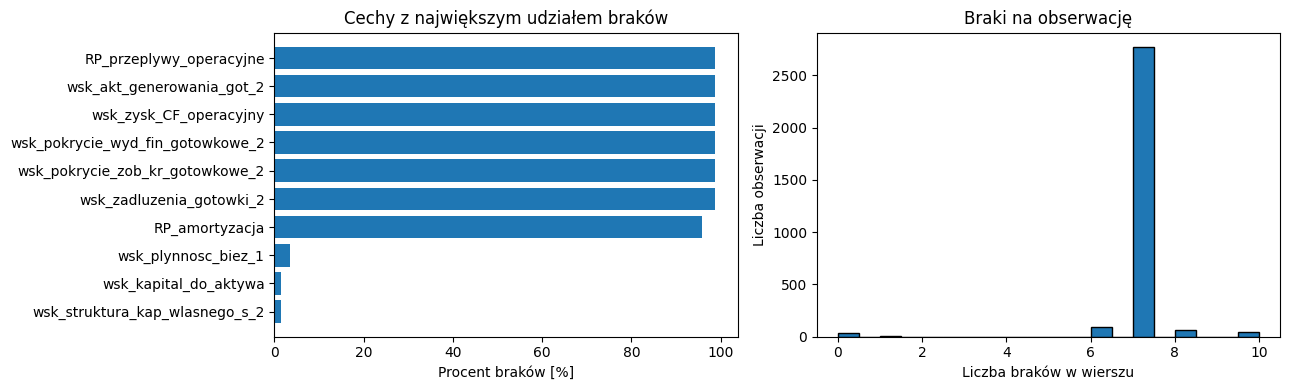

In [167]:
print("Łączna liczba braków w danych X_raw:", X_raw.isna().sum().sum())
braki = X_raw.isna().sum(); braki = braki[braki > 0]
braki_df = pd.DataFrame({"cecha": braki.index, "braki": braki.values, "procent braków": braki.values / len(X_raw) * 100}).sort_values("procent braków", ascending=False).round(2)
display(braki_df)

braki_w_wierszu = X_raw.isna().sum(axis=1)
print("Liczba obserwacji z co najmniej jednym brakiem:", (braki_w_wierszu > 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = braki_df.query("braki > 0").head(20).iloc[::-1]
if len(top):
    axes[0].barh(top["cecha"], top["procent braków"])
axes[0].set_xlabel("Procent braków [%]")
axes[0].set_title("Cechy z największym udziałem braków")
axes[1].hist(braki_w_wierszu, bins=20, edgecolor="black")
axes[1].set_xlabel("Liczba braków w wierszu")
axes[1].set_ylabel("Liczba obserwacji")
axes[1].set_title("Braki na obserwację")
plt.tight_layout()
plt.show()

Braki danych o łącznej liczbie 20854 są silnie skoncentrowane w niewielkiej liczbie zmiennych, głównie dotyczących przepływów pieniężnych i wskaźników z nimi powiązanych.

### 1.5. Powtarzające się obserwacje, identyczne kolumny i mocno skorelowane cechy

In [165]:
print("Liczba zduplikowanych obserwacji:", X_raw.duplicated().sum())
print("Liczba zduplikowanych cech:", X_raw.T.duplicated().sum())
print("Zduplikowane cechy:", X_raw.columns[X_raw.T.duplicated()].tolist())
for i, col in enumerate(X_raw.columns):
    for prev_col in X_raw.columns[:i]:
        if X_raw[col].equals(X_raw[prev_col]):
            print(f"\t{col} - jest duplikatem - {prev_col}")
            break

corr = X_raw[num_cols].corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
silne = corr.where(mask).stack()
silne = silne[silne.abs() > 0.9]
silne_df = silne.reset_index()
silne_df.columns = ["cecha 1", "cecha 2", "korelacja (>0.9)"]
silne_df = silne_df.reindex(silne_df["korelacja (>0.9)"].abs().sort_values(ascending=False).index)
print("\nLiczba par z |r| > 0.9:", len(silne_df))
print("Liczba par z |r| ≈ 1.0:", np.isclose(silne_df["korelacja (>0.9)"].abs(), 1.0, atol=EPS, rtol=0).sum())
display(silne_df.round(6))

Liczba zduplikowanych obserwacji: 0
Liczba zduplikowanych cech: 8
Zduplikowane cechy: ['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1']
	wsk_rent_sprzedazy - jest duplikatem - wsk_ROS
	wsk_zysk_operacyjny_zob_1 - jest duplikatem - wsk_zysk_op_zobowiazania
	wsk_zadluzenie_gotowka - jest duplikatem - wsk_koszty_odsetki_przychody
	wsk_ebitda_zobowiazan_odsetki_1 - jest duplikatem - wsk_ebitda_koszty_odsetkowe_1
	wsk_ebitda_zobowiazan_odsetki_2 - jest duplikatem - wsk_ebitda_koszty_odsetkowe_2
	wsk_poziom_kosztow_operacyjnych - jest duplikatem - wsk_koszty_przychody
	wsk_poziom_kosztow_finansowych - jest duplikatem - wsk_koszty_fin_przychody
	wsk_struktura_kap_wlasnego_1 - jest duplikatem - wsk_udzial_kap_wlasnego_aktywa_1

Liczba par z |r| > 0.9: 179
Liczba par z |r| ≈ 1.0: 19


,cecha 1,cecha 2,korelacja (>0.9)
29,wsk_kapital_do_aktywa,wsk_struktura_kap_wlasnego_1,1.000000
27,wsk_kapital_do_aktywa,wsk_udzial_kap_wlasnego_aktywa_1,1.000000
60,wsk_ROS,wsk_rent_sprzedazy,1.000000
115,wsk_koszty_odsetki_przychody,wsk_zadluzenie_gotowka,1.000000
119,wsk_udzial_kap_wlasnego_aktywa_1,wsk_struktura_kap_wlasnego_1,1.000000
...,...,...,...
151,wsk_ebitda_zobowiazan_odsetki_2,wsk_udzial_zob_biez_sprzedaz_1,0.900863
145,wsk_ebitda_koszty_odsetkowe_2,wsk_udzial_zob_biez_sprzedaz_1,0.900863
144,wsk_ebitda_koszty_odsetkowe_2,wsk_rotacja_zobowiazan,0.900710
150,wsk_ebitda_zobowiazan_odsetki_2,wsk_rotacja_zobowiazan,0.900710


### 1.6. Weryfikacja cech stałych lub prawie stałych (z udziałem dominującej wartości >0.99)

In [170]:
dominujaca = X_raw.apply(lambda s: s.value_counts(normalize=True, dropna=False).max())
prawie_stale = dominujaca[dominujaca > 0.99]
display(pd.DataFrame({"cecha stała lub prawie stała": prawie_stale.index, "liczba unikalnych wartości": [X_raw[c].nunique(dropna=False) for c in prawie_stale.index],
    "wartość dominująca": [X_raw[c].value_counts(dropna=False).idxmax() for c in prawie_stale.index],
    "udział dominującej wartości": prawie_stale.values.round(6)}))

,cecha stała lub prawie stała,liczba unikalnych wartości,wartość dominująca,udział dominującej wartości
0,szczegolnaFormaPrawna_Symbol,1,117.0,1.000000
1,Wartosc_firmy,29,0.0,0.990667
2,Naleznosci_dostaw_uslug_pow12m_powiazane,6,0.0,0.998333
3,Naleznosci_dostaw_uslug_pow12m_kapitale,2,0.0,0.999667
4,Pozostale_rezerwy,16,0.0,0.995000
5,Zobowiazania_dostaw_uslug_pow12m_powiazane,4,0.0,0.999000
6,Zobowiazania_dostaw_uslug_12m_kapitale,21,0.0,0.993333
7,Zobowiazania_dostaw_uslug_pow12m_kapitale,2,0.0,0.999667
8,Ujemna_wartosc_firmy,7,0.0,0.998000
9,Zobowiazania_dostaw_uslug_pow12m,25,0.0,0.991333


### Wartości nieskończone i znaki

In [185]:
X_num = X_raw.select_dtypes(include="number")
inf_counts = X_num.apply(lambda s: np.isposinf(s.to_numpy(dtype=float, na_value=np.nan)).sum())
minus_inf_counts = X_num.apply(lambda s: np.isneginf(s.to_numpy(dtype=float, na_value=np.nan)).sum())
print("Łączna liczba inf w danych:", inf_counts.sum())
print("Łączna liczba -inf w danych:", minus_inf_counts.sum())
inf_counts = inf_counts[inf_counts > 0]
display(inf_counts.sort_values(ascending=False).to_frame("liczba inf"))

X_num_finite = X_num.replace([np.inf, -np.inf], np.nan)

liczba_niebrakujacych = X_num_finite.notna().sum()
liczba_zer = (X_num_finite == 0).sum()
udzial_zer = liczba_zer.div(liczba_niebrakujacych.replace(0, np.nan))
duzo_zer = pd.DataFrame({"liczba obserwacji": liczba_niebrakujacych, "liczba zer": liczba_zer,
                         "udział zer": udzial_zer, "liczba unikalnych wartości": X_num_finite.nunique()})
duzo_zer = duzo_zer[duzo_zer["udział zer"] > 0.9]
print("\nLiczba cech z udziałem zer > 0.9:", len(duzo_zer))
display(duzo_zer.sort_values("udział zer", ascending=False).round(4).head(15))

Łączna liczba inf w danych: 1005
Łączna liczba -inf w danych: 0


,liczba inf
wsk_plynnosc_biez_1,901
wsk_struktura_kap_wlasnego_s_2,98
wsk_kapital_do_aktywa,6



Liczba cech z udziałem zer > 0.9: 33


,liczba obserwacji,liczba zer,udział zer,liczba unikalnych wartości
Naleznosci_dostaw_uslug_pow12m_kapitale,3000,2999,0.9997,2
Zobowiazania_dostaw_uslug_pow12m_kapitale,3000,2999,0.9997,2
Zobowiazania_dostaw_uslug_pow12m_powiazane,3000,2997,0.9990,4
Naleznosci_dostaw_uslug_pow12m_powiazane,3000,2995,0.9983,6
Ujemna_wartosc_firmy,3000,2994,0.9980,7
Pozostale_rezerwy,3000,2985,0.9950,16
Zobowiazania_dostaw_uslug_12m_kapitale,3000,2980,0.9933,21
Zobowiazania_dostaw_uslug_pow12m,3000,2974,0.9913,25
Wartosc_firmy,3000,2972,0.9907,29
Zobowiazania_dostaw_uslug_pow12m_pozostale,3000,2970,0.9900,31


Wstępna analiza jakości danych wykazała występowanie braków skoncentrowanych w wybranych zmiennych, wartości nieskończonych oraz cech zdominowanych przez konkretną wartość. Zidentyfikowane zostały również liczne silne zależności liniowe między cechami. Uzyskane wyniki wskazują na konieczność odpowiedniego przygotowania danych, przed przystąpieniem do trenowania modeli.

## ETAP 2 - 